# Vector-Space Character Similarity in TV Scripts

Each character of a soap-opera script is represented as a document of their spoken lines; the goal is a vector space in which every character's held-out lines are retrieved closest to their own training vector. The notebook improves pre-processing, linguistic features (POS, n-grams, TF-IDF weighting), adds dialogue context and scene features, runs a systematic parameter search, and analyses the similarity rankings.

**Final test: 15 of 16 characters correctly retrieved (93.75%).**


In [1]:
!pip install nltk

In [2]:
import string
import re
import numpy as np
from numpy.linalg import norm
import pandas as pd
from collections import Counter, OrderedDict

import seaborn as sns
import matplotlib.pyplot as plt

import math

import nltk

from sklearn.feature_extraction import DictVectorizer

%matplotlib inline
pd.options.display.max_colwidth=500

In [3]:
nltk.download('averaged_perceptron_tagger_eng')

True

In [4]:
# Load in training data and display in pandas dataframe
train_path='training.csv'
train_data = pd.read_csv(train_path,  delimiter="\t", skip_blank_lines = True)
val_path ='val.csv'
val_data = pd.read_csv(val_path,  delimiter="\t", skip_blank_lines = True)
test_path ='test.csv'
test_data = pd.read_csv(test_path,  delimiter="\t", skip_blank_lines = True)

# Inspect
train_data

,Episode,Scene,Scene_info,Character_name,Line,Gender
0,1350,1,DESERTED CAR PARK EXT NIGHT,SHIRLEY,"Look at ya, not a mark on ya. And you think you're an unlucky man.",FEMALE
1,1350,1,DESERTED CAR PARK EXT NIGHT,OTHER,Shirl...,MALE
2,1350,2,R&R INT NIGHT,JACK,Oi. Where have you been? Huh? What were the texts about?,MALE
3,1350,2,R&R INT NIGHT,RONNIE,Nothing. Nothing. I'll be with you in two minutes yeah?,FEMALE
4,1350,2,R&R INT NIGHT,JACK,"Well I've got mates here I wanted to have a chat with them, instead I've been serving behind the bar.",MALE
...,...,...,...,...,...,...
14008,1399,55,SQUARE EXT DAY LIGHT,OTHER,"Dad? Okay ... alright, just one drink alright. But that's all. It doesn't mean anything. It's just a drink.",MALE
14009,1399,55,SQUARE EXT DAY LIGHT,MAX,Thanks Bradley. Thanks mate... It means the world to me...,MALE
14010,1399,55,SQUARE EXT DAY LIGHT,OTHER,You alright...,MALE
14011,1399,55,SQUARE EXT DAY LIGHT,MAX,"Yeah, yeah, yeah. I'm fine.",MALE


edited q3 func

In [5]:
def create_character_document_from_dataframe(df, max_line_count=300, include_context=False):
    """
    character document creation with adjustable parameters for grid search.
    params:
    ::max_line_count:: Maximum number of lines per character.
    ::include_context:: To include context from other characters in the same scene or not.
    returns:
    a dictionary of character documents.
    """
    character_docs = {}
    character_line_count = {}

    grouped = df.groupby(['Episode', 'Scene'])

    for (episode, scene), group in grouped:
        # drop NaNs to only keep str
        scene_lines = group['Line'].dropna().astype(str).tolist() 

        for _, row in group.iterrows():
            char_name = row['Character_name']
            line = row['Line']

            if isinstance(line, float) and np.isnan(line): 
                continue
            # convert line to string
            line = str(line)  
            if char_name not in character_docs:
                character_docs[char_name] = ""
                character_line_count[char_name] = 0

            if character_line_count[char_name] == max_line_count:
                continue
            # includeing context or not (Q3)
            context = ""
            if include_context:
                context_lines = [l for l in scene_lines if l != line]
                context = " ".join(context_lines)

            character_docs[char_name] += line + " _EOL_ " + context + " _SCENE_ " # adding an end-of-line and scene token 
            character_line_count[char_name] += 1

    return character_docs

In [6]:
# print out the number of words each character has in the training set
# only use the first 300 lines of each character
train_character_docs = create_character_document_from_dataframe(train_data, max_line_count=300)
print('Num. Characters: ',len(train_character_docs.keys()),"\n")
total_words = 0
for name in train_character_docs.keys():
    print(name, 'Number of Words: ',len(train_character_docs[name].split()))
    total_words += len(train_character_docs[name].split())
print("total words", total_words)

Num. Characters:  16 

SHIRLEY Number of Words:  3400
OTHER Number of Words:  2973
JACK Number of Words:  4007
RONNIE Number of Words:  3305
ROXY Number of Words:  3419
TANYA Number of Words:  3591
SEAN Number of Words:  3168
MAX Number of Words:  4184
IAN Number of Words:  3767
JANE Number of Words:  3428
STACEY Number of Words:  3535
PHIL Number of Words:  3429
HEATHER Number of Words:  3562
MINTY Number of Words:  3610
CHRISTIAN Number of Words:  3578
CLARE Number of Words:  3923
total words 56879


In [7]:
import string
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import nltk

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
from nltk.stem import PorterStemmer

def pre_process(character_text, lower=True, remove_punctuation=True, remove_stopwords=True, lemmatize=True, stemming=False):
    """
    pre-processing is done for the params listed below
    params:
    ::lower:: Convert text to lowercase.
    ::remove_punctuation:: Remove punctuation from text.
    ::remove_stopwords:: Remove common stopwords.
    ::lemmatize:: Apply lemmatization.
    ::stemming:: Apply stemming to reduce words to their root forms.
    returns:
    a list of pre-processed tokens.
    """
  
    stop_words = set(stopwords.words('english')) if remove_stopwords else set()
    lemmatizer = WordNetLemmatizer() if lemmatize else None
    stemmer = PorterStemmer() if stemming else None
    # lowercase
    if lower:
        character_text = character_text.lower()
    #punctuation remover
    if remove_punctuation:
        character_text = character_text.translate(str.maketrans('', '', string.punctuation))
    #splitting based on whitespace
    tokens = re.split(r'\s+', character_text)
    # stopword remover
    if remove_stopwords:
        tokens = [word for word in tokens if word not in stop_words]
    # lemmatization
    if lemmatize:
        tokens = [lemmatizer.lemmatize(word) for word in tokens if word.isalpha()]
    # stemming
    if stemming:
        tokens = [stemmer.stem(word) for word in tokens]

    return tokens


In [8]:
# create list of pairs of (character name, pre-processed character) 
training_corpus = [(name, pre_process(doc)) for name, doc in sorted(train_character_docs.items())]
train_labels = [name for name, doc in training_corpus]

In [9]:
!pip install textblob

In [10]:

from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.feature_extraction.text import TfidfVectorizer
from textblob import TextBlob
from nltk import pos_tag, word_tokenize, ngrams
from collections import Counter
import numpy as np

# Initialize global transformers and selector
tfidf_transformer = TfidfTransformer()
selector = None  # global selector for reuse during validation
vectorizer = None  # global TF-IDF vectorizer

def to_feature_vector_dictionary(character_doc, ngram_range=(1, 1), use_pos_tags=False, use_sentiment=False):
    """
    Feature extraction with n-grams, POS tags, and sentiment analysis.

    params:
    ::ngram_range:: The range of n-grams to extract.
    ::use_pos_tags:: To include POS tags as features or not.
    ::use_sentiment:: To include sentiment analysis features or not.

    returns:
    a dict of features.
    """
    counts = Counter(character_doc)

    # n-grams extraction
    for n in range(ngram_range[0], ngram_range[1] + 1):
        for ngram in ngrams(character_doc, n):
            counts["_".join(ngram)] += 1

    # POS tags
    if use_pos_tags:
        pos_tags = pos_tag(character_doc)
        for word, pos in pos_tags:
            counts[f'POS_{pos}'] += 1

    # sentiment analysis
    if use_sentiment:
        blob = TextBlob(" ".join(character_doc))
        counts["SENTIMENT_POSITIVE"] = max(blob.sentiment.polarity, 0)
        counts["SENTIMENT_NEGATIVE"] = abs(min(blob.sentiment.polarity, 0))

    return dict(counts)

q2 func

In [11]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.exceptions import NotFittedError
from collections import Counter

tfidf_transformer = TfidfTransformer()
corpusVectorizer = DictVectorizer()
selector = None

def create_document_matrix_from_corpus(
    corpus, fitting=False, ngram_range=(1, 1), use_pos_tags=False, use_sentiment=False,
    max_df=0.9, min_df=2,k_best_features=700
):
    """
    create document-term matrix with TF-IDF transformation and filtering by document frequency.
    params:
    ::fitting:: Whether to fit the vectorizer and transformers.
    ::ngram_range:: The range of n-grams to extract.
    ::use_pos_tags:: To include POS tags as features or not.
    ::use_sentiment:: To include sentiment analysis features or not.
    ::max_df:: Maximum document frequency for filtering tokens.
    ::min_df:: Minimum document frequency for filtering tokens.
    returns:
    A document-term matrix.
    """
    global tfidf_transformer, corpusVectorizer,selector

    # feature dictionaries
    feature_dicts = [
        to_feature_vector_dictionary(doc, ngram_range=ngram_range, use_pos_tags=use_pos_tags, use_sentiment=use_sentiment)
        for _, doc in corpus
    ]

    # max_df and min_df filtering
    if fitting:
        document_frequencies = Counter()
        for feature_dict in feature_dicts:
            document_frequencies.update(feature_dict.keys())

        num_docs = len(feature_dicts)
        filtered_feature_dicts = []

        for feature_dict in feature_dicts:
            filtered_dict = {
                key: value
                for key, value in feature_dict.items()
                if min_df <= (document_frequencies[key] / num_docs) <= max_df
            }
            if not filtered_dict:  # check to include at least some features
                filtered_dict = feature_dict
            filtered_feature_dicts.append(filtered_dict)

        feature_dicts = filtered_feature_dicts

    # fit or transform the DictVectorizer
    if fitting:
        corpusVectorizer.fit(feature_dicts)
    
    doc_feature_matrix = corpusVectorizer.transform(feature_dicts)
    

    # tf-idf
    if fitting:
        tfidf_transformer.fit(doc_feature_matrix)
    doc_feature_matrix = tfidf_transformer.transform(doc_feature_matrix)

    # K-Best feature Selection 
    if fitting:
        selector = SelectKBest(chi2, k=min(k_best_features, doc_feature_matrix.shape[1]))
        labels = [label for label, _ in corpus]
        selector.fit(doc_feature_matrix, labels)
    if selector is not None:
        doc_feature_matrix = selector.transform(doc_feature_matrix)
    return doc_feature_matrix


training_feature_matrix = create_document_matrix_from_corpus(training_corpus, fitting=True)


In [12]:
training_feature_matrix

<16x700 sparse matrix of type '<class 'numpy.float64'>'
	with 1665 stored elements in Compressed Sparse Row format>

In [13]:
# get the validation data- only 50 lines used for each character
val_character_docs = create_character_document_from_dataframe(val_data, max_line_count=50)
print('Num. Characters: ',len(val_character_docs.keys()),"\n")
total_words = 0
for name in val_character_docs.keys():
    print(name, 'Num of Words: ',len(val_character_docs[name].split()))
    total_words += len(val_character_docs[name].split())
print("total words", total_words)

# create list of pairs of (character name, pre-processed character) 
val_corpus = [(name, pre_process(doc)) for name, doc in sorted(val_character_docs.items())]
val_labels = [name for name, doc in val_corpus]

Num. Characters:  16 

OTHER Num of Words:  513
HEATHER Num of Words:  557
TANYA Num of Words:  537
JACK Num of Words:  541
RONNIE Num of Words:  416
JANE Num of Words:  646
STACEY Num of Words:  558
SEAN Num of Words:  563
PHIL Num of Words:  398
SHIRLEY Num of Words:  633
ROXY Num of Words:  357
IAN Num of Words:  712
MINTY Num of Words:  653
CHRISTIAN Num of Words:  377
CLARE Num of Words:  477
MAX Num of Words:  615
total words 8553


In [14]:
# Just transform the val_feature_matrix, don't fit
val_feature_matrix = create_document_matrix_from_corpus(val_corpus, fitting=False)

In [15]:
val_feature_matrix

<16x700 sparse matrix of type '<class 'numpy.float64'>'
	with 372 stored elements in Compressed Sparse Row format>

In [16]:
def compute_cosine_similarity(v1, v2):
    """Takes a pair of vectors v1 and v2 (1-d arrays e.g. [0, 0.5, 0.5])
    returns the cosine similarity between the vectors
    """
    
    # compute cosine similarity manually
    manual_cosine_similarity = np.dot(v1, v2)  /(norm(v1) * norm(v2))
    
    return manual_cosine_similarity

In [17]:
def compute_IR_evaluation_scores(train_feature_matrix, test_feature_matrix, train_labels, test_labels):
    """
    Computes an information retrieval based on training data feature matrix and test data feature matrix
    returns 4-tuple:
    ::mean_rank:: mean of the ranking of the target document in terms of similarity to the query/test document
    1 is the best possible score.
    ::mean_cosine_similarity:: mean cosine similarity score for the target document vs. the test document of the same class
    ::accuracy:: proportion of test documents correctly classified
    ::df:: a data frame with all the similarity measures of the test documents vs. train documents
    
    params:
    ::train_feature_matrix:: a numpy matrix N x M shape where N = number of characters M = number of features
    ::test_feature_matrix::  a numpy matrix N x M shape where N = number of characters M = number of features
    ::train_labels:: a list of character names for the training data in order consistent with train_feature_matrix
    ::test_labels:: a list of character names for the test data in order consistent with test_feature_matrix
    """
    rankings = []
    all_cosine_similarities = []
    pairwise_cosine_similarity = []
    pairs = []
    correct = 0
    for i, target in enumerate(test_labels):
        # compare the left out character against the mean
        idx = i 
        fm_1 = test_feature_matrix.toarray()[idx]
        all_sims = {}
        # print("target:", target)
        for j, other in enumerate(train_labels):
            fm_2 = train_feature_matrix.toarray()[j]
            manual_cosine_similarity = compute_cosine_similarity(fm_1, fm_2)
            pairs.append((target, other))
            pairwise_cosine_similarity.append(manual_cosine_similarity)
            if other == target:
                all_cosine_similarities.append(manual_cosine_similarity)
            all_sims[other] = manual_cosine_similarity

            # print(target, other, manual_cosine_similarity)
        sorted_similarities = sorted(all_sims.items(),key=lambda x:x[1],reverse=True)
        # print(sorted_similarities)
        ranking = {key[0]: rank for rank, key in enumerate(sorted_similarities, 1)}
        # print("Ranking for target", ranking[target])
        if ranking[target] == 1:
            correct += 1
        rankings.append(ranking[target])
        # print("*****")
    mean_rank = np.mean(rankings)
    mean_cosine_similarity = np.mean(all_cosine_similarities)
    accuracy = correct/len(test_labels)
    print("mean rank", np.mean(rankings))
    print("mean cosine similarity", mean_cosine_similarity)
    print(correct, "correct out of", len(test_labels), "/ accuracy:", accuracy )
    
    # get a dafaframe showing all the similarity scores of training vs test docs
    df = pd.DataFrame({'doc1': [x[0] for x in pairs], 'doc2': [x[1] for x in pairs],
                       'similarity': pairwise_cosine_similarity})

    # display characters which are most similar and least similar
    df.loc[[df.similarity.values.argmax(), df.similarity.values.argmin()]]
    return (mean_rank, mean_cosine_similarity, accuracy, df)

In [18]:
def plot_heat_map_similarity(df):
    """Takes a dataframe with header 'doc1, doc2, similarity'
    Plots a heatmap based on the similarity scores.
    """
    test_labels =  sorted(list(set(df.sort_values(['doc1'])['doc1'])))
    # add padding 1.0 values to either side
    cm = [[1.0,] * (len(test_labels)+2)]
    for target in test_labels:
        new_row = [1.0]
        for x in df.sort_values(['doc1', 'doc2'])[df['doc1']==target]['similarity']:
            new_row.append(x)
        new_row.append(1.0)
        cm.append(new_row)
    cm.append([1.0,] * (len(test_labels)+2))
    #print(cm)
    labels = [""] + test_labels + [""]
    fig = plt.figure(figsize=(20,20))
    ax = fig.add_subplot(111)
    cax = ax.matshow(cm)
    plt.title('Similarity matrix between documents as vectors')
    fig.colorbar(cax)
    ax.set_xticks(np.arange(len(labels)))
    ax.set_yticks(np.arange(len(labels)))
    ax.set_xticklabels( labels, rotation=45)
    ax.set_yticklabels( labels)

    for i in range(len(cm)):
        for j in range(len(cm)):

            text = ax.text(j, i, round(cm[i][j],3),
                           ha="center", va="center", color="w")

    plt.xlabel('Training Vector Doc')
    plt.ylabel('Test Vector Doc')
    #fig.tight_layout()
    plt.show()

In [19]:
mean_rank, mean_cosine_simliarity, acc, df = compute_IR_evaluation_scores(training_feature_matrix, val_feature_matrix, train_labels, val_labels)

mean rank 1.75
mean cosine similarity 0.41289395999095196
14 correct out of 16 / accuracy: 0.875


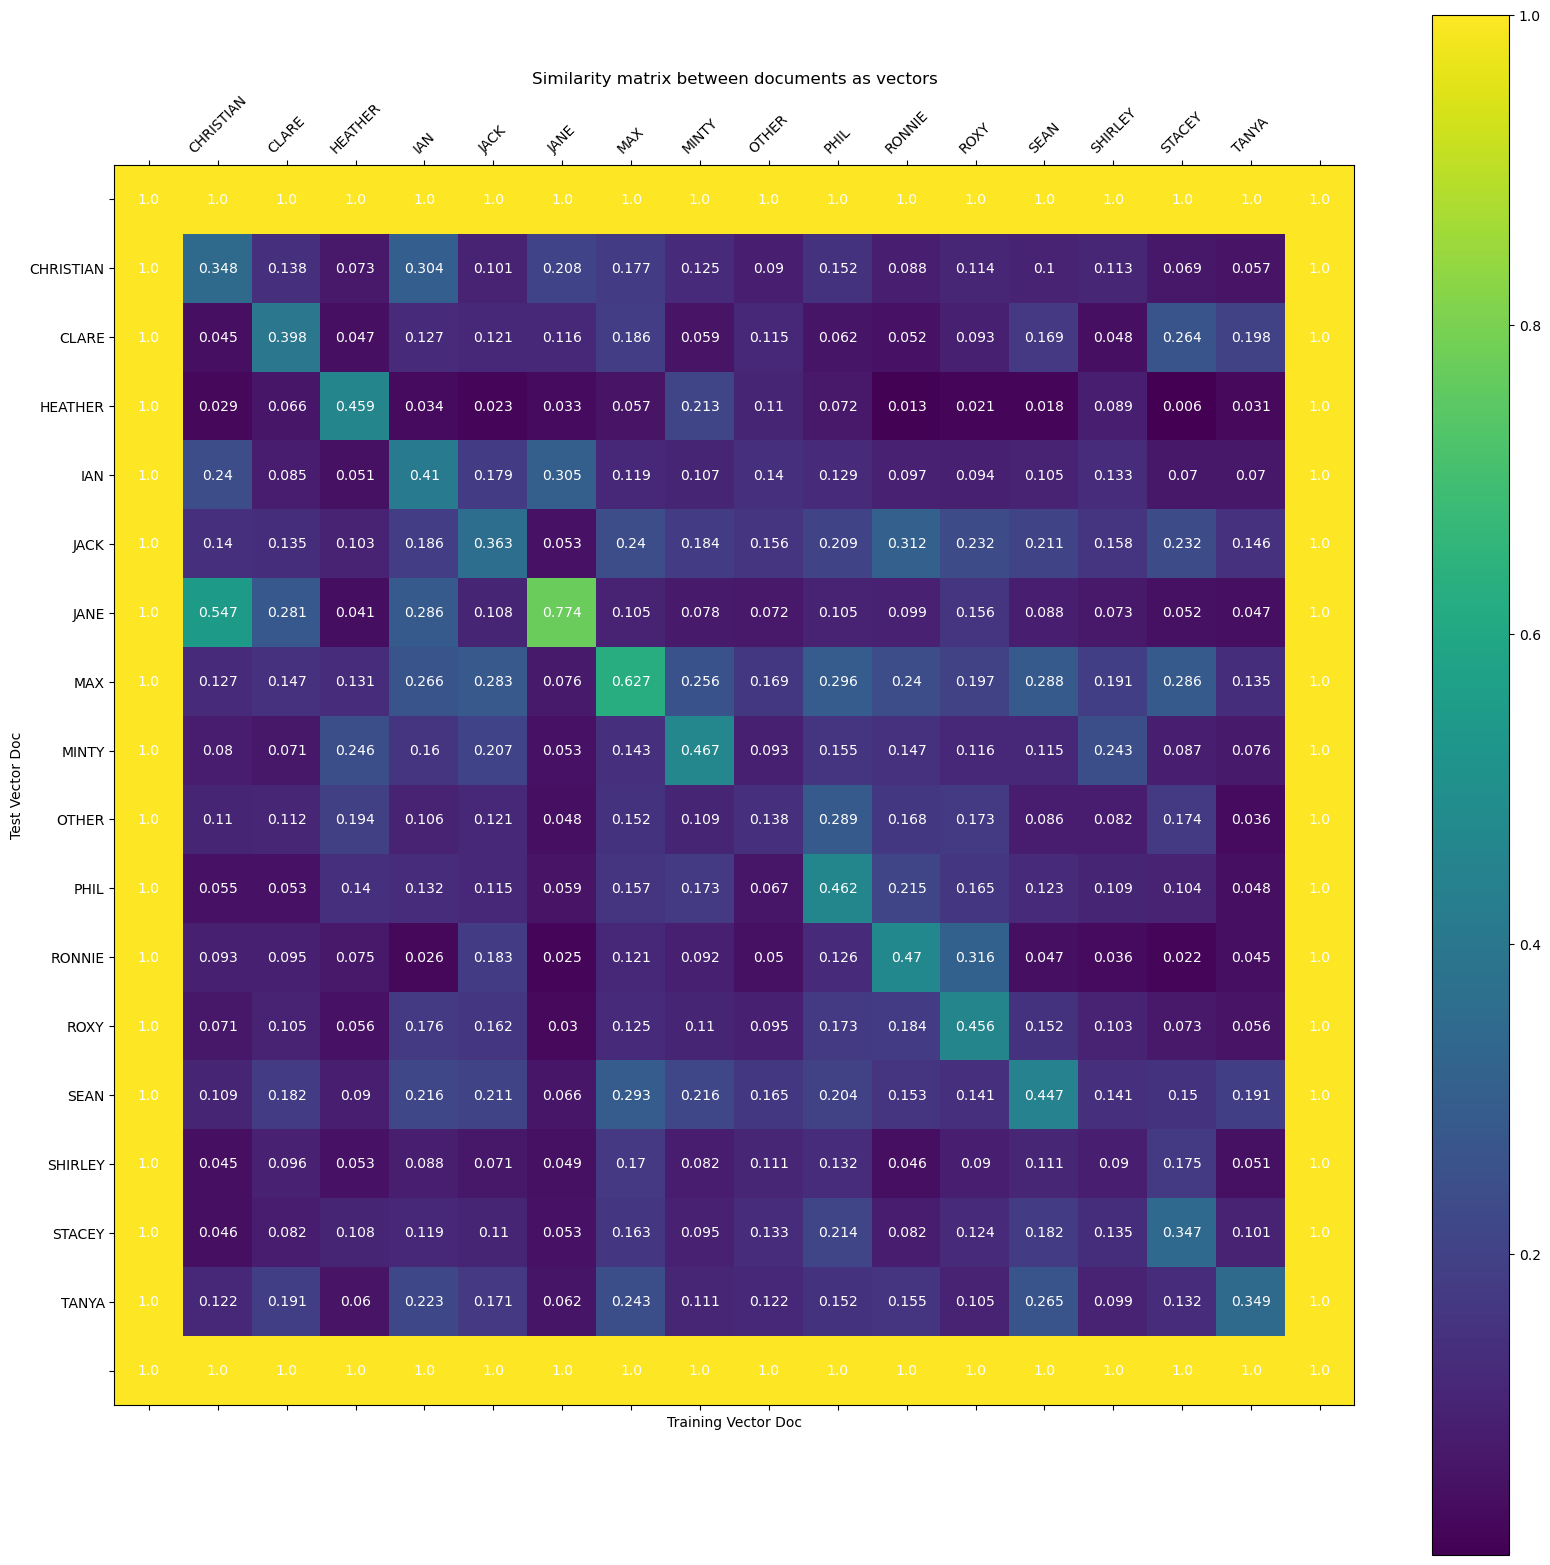

In [20]:
plot_heat_map_similarity(df)

## Part 1: Improve pre-processing
Using the pre-processing techniques you have learned in the module, improve the `pre_process` function above, which currently just tokenizes text based on white space.

When developing, use the first 300 and 50 lines from the training and validation files, as per above. To check the improvements by using the different techniques, use the `compute_IR_evaluation_scores` function as above. The **mean rank** is the main metric you need to focus on improving throughout this project, where the target/best possible performance is **1** (i.e. all test/validation data character documents are closest to their corresponding training data character documents) and the worst is **16**. Initially, the code in this template achieves a mean rank of **4.3**  and accuracy of **0.25** on the test set and a mean rank of **3.6** and accuracy of **0.31** on the validation set - you should be looking to improve those, particularly getting the mean rank as close to 1 as possible.


## Part 2: Improve linguistic feature extraction
Use the feature extraction techniques you have learned to improve the `to_feature_vector_dictionary` and `create_document_matrix_from_corpus` functions above. Examples of extra features could include extracting n-grams of different lengths and including POS tags. You could also use sentiment analysis or another text classifier's result when applied to the features for each character document. You could even use a gender classifier trained on the same data using the GENDER column **(but DO NOT USE the GENDER column directly in the features for the final vector)**.

Matrix transformation techniques like TF-IDF (https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfTransformer.html) are commonly used to improve the `create_document_matrix_from_corpus` function, which currently only uses a dictionary vectorizer (`DictVectorizer`) which straight-forwardly maps from the feature dictionaries produced for each character document to a sparse matrix.

Other options include using feature selection/reduction with techniques like minimum/maximum document frequency and/or feature selection like k-best selection using different statistical tests https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectKBest.html. 

Again, develop your system using the training and validation sets and note the effect/improvement in mean rank with the techniques you use.

## Part 3: Add dialogue context and scene features
Adjust `create_character_document_from_dataframe` and the other functions appropriately so the data incorporates the context of the line spoken by the characters in terms of the lines spoken by other characters in the same scene (before and after the target character's lines). HINT: you should use the *Episode* and *Scene* columns to check which characters are in the same scene to decide whether to include their lines or not. Only the lines from the same *Scene* can be added as the context as lines from different *Scene* are irrelevant.  **(but DO NOT USE the GENDER and CHARACTER columns directly)**.

## Part 4: Parameter Search
It is a good practice to conduct a systematic parameter search instead of a random search as this will give you more 
reliable results. Given the scope of this project, it is possible to conduct a **grid search** on options you decided to try within the individual questions. The grid search should be done within the individual questions (i.e. Q1-Q3), and the later question should adopt the best settings from the previous questions. There is no need to do a grid search over all configurations from all questions as this will easily make the search unrealistic. E.g. Suppose we need 32, 90, and 4 runs to finish the grid search within questions, a cross-question grid search would need 32x90x4 = 11520 runs!                                                                      

In [21]:
from sklearn.model_selection import ParameterGrid
def grid_search_q1(train_data, val_data):
    preprocess_params = {
        'lower': [True, False],
        'remove_punctuation': [True, False],
        'remove_stopwords': [True, False],
        'lemmatize': [True, False],
        'stemming': [True, False]
    }

    param_grid = ParameterGrid(preprocess_params)
    results = []

    for params in param_grid:
        print(f"Testing preprocessing params: {params}")

        # creating character documents for training and validation
        train_character_docs = create_character_document_from_dataframe(train_data, max_line_count=300)
        val_character_docs = create_character_document_from_dataframe(val_data, max_line_count=50)

        # preprocessing training and validation data
        train_corpus = [(name, pre_process(doc, **params)) for name, doc in train_character_docs.items()]
        val_corpus = [(name, pre_process(doc, **params)) for name, doc in val_character_docs.items()]

        # matrix generation
        train_matrix = create_document_matrix_from_corpus(train_corpus, fitting=True)
        val_matrix = create_document_matrix_from_corpus(val_corpus, fitting=False)
        #performance eval
        mean_rank, mean_cosine_similarity, accuracy, _ = compute_IR_evaluation_scores(train_matrix,val_matrix,[name for name, _ in train_corpus],[name for name, _ in val_corpus]
        )

        #storing results
        results.append({
            'params': params,
            'mean_rank': mean_rank,
            'accuracy': accuracy,
            'mean_cosine_similarity': mean_cosine_similarity
        })

    # sort results and return the best settings
    best_result = sorted(results, key=lambda x: x['mean_rank'])[0]
    print("Best Q1 Result:", best_result)
    return best_result['params']


In [22]:
from sklearn.model_selection import ParameterGrid

def grid_search_q2(train_data, val_data, q1_best_params):
    
    feature_params = {
        'ngram_range': [(1, 1), (1, 2)],
        'use_pos_tags': [True, False],
        'use_sentiment': [True, False],
        'max_df': [0.7, 0.9],
        'min_df': [1, 2, 3],
        'k_best_features':[500,700,900]
    }

    param_grid = ParameterGrid(feature_params)
    results = []

    for params in param_grid:
        print(f"Testing feature extraction params: {params}")

        # creating character documents for training and validation
        train_character_docs = create_character_document_from_dataframe(train_data, max_line_count=300)
        val_character_docs = create_character_document_from_dataframe(val_data, max_line_count=50)

        # preprocess training and validation data using best Q1 settings
        train_corpus = [(name, pre_process(doc, **q1_best_params)) for name, doc in train_character_docs.items()]
        val_corpus = [(name, pre_process(doc, **q1_best_params)) for name, doc in val_character_docs.items()]

        # feature matrix with dynamic parameters
        train_matrix = create_document_matrix_from_corpus(train_corpus,fitting=True,ngram_range=params['ngram_range'],use_pos_tags=params['use_pos_tags'],use_sentiment=params['use_sentiment'],max_df=params['max_df'],min_df=params['min_df'],k_best_features=params["k_best_features"])

        val_matrix = create_document_matrix_from_corpus(val_corpus,fitting=False,ngram_range=params['ngram_range'],use_pos_tags=params['use_pos_tags'],use_sentiment=params['use_sentiment'],max_df=params['max_df'],min_df=params['min_df'],k_best_features=params["k_best_features"])

        # performance eval
        mean_rank, mean_cosine_similarity, accuracy, _ = compute_IR_evaluation_scores(
            train_matrix,
            val_matrix,
            [name for name, _ in train_corpus],
            [name for name, _ in val_corpus]
        )

        # store results
        results.append({
            'params': params,
            'mean_rank': mean_rank,
            'accuracy': accuracy,
            'mean_cosine_similarity': mean_cosine_similarity
        })

    # sort results and return the best settings
    best_result = sorted(results, key=lambda x: x['mean_rank'])[0]
    print("Best Q2 Result:", best_result)
    return best_result['params']


In [23]:
def grid_search_q3(train_data, val_data, q1_best_params, q2_best_params):
    context_params = {
        'max_line_count': [200, 250, 300],
        'include_context': [True, False]
    }

    param_grid = ParameterGrid(context_params)
    results = []

    for params in param_grid:
        print(f"Testing context params: {params}")

        # creating character documents
        train_character_docs = create_character_document_from_dataframe(
            train_data,
            max_line_count=params['max_line_count'],
            include_context=params['include_context']
        )
        val_character_docs = create_character_document_from_dataframe(
            val_data,
            max_line_count=params['max_line_count'],
            include_context=params['include_context']
        )

        # preprocess text using best Q1 settings
        train_corpus = [(name, pre_process(doc, **q1_best_params)) for name, doc in train_character_docs.items()]
        val_corpus = [(name, pre_process(doc, **q1_best_params)) for name, doc in val_character_docs.items()]

        # feature matrix using best Q2 settings
        train_matrix = create_document_matrix_from_corpus(
            train_corpus,
            fitting=True,
            ngram_range=q2_best_params['ngram_range'],
            use_pos_tags=q2_best_params['use_pos_tags'],
            use_sentiment=q2_best_params['use_sentiment'],
            max_df=q2_best_params['max_df'],
            min_df=q2_best_params['min_df'],
            k_best_features=q2_best_params['k_best_features']

        )

        val_matrix = create_document_matrix_from_corpus(
            val_corpus,
            fitting=False,
            ngram_range=q2_best_params['ngram_range'],
            use_pos_tags=q2_best_params['use_pos_tags'],
            use_sentiment=q2_best_params['use_sentiment'],
            max_df=q2_best_params['max_df'],
            min_df=q2_best_params['min_df'],
            k_best_features=q2_best_params['k_best_features']
        )

        # performance eval
        mean_rank, mean_cosine_similarity, accuracy, _ = compute_IR_evaluation_scores(train_matrix,val_matrix,[name for name, _ in train_corpus],[name for name, _ in val_corpus])

        # store results
        results.append({
            'params': params,
            'mean_rank': mean_rank,
            'accuracy': accuracy,
            'mean_cosine_similarity': mean_cosine_similarity
        })

    # sort results and return the best settings
    best_result = sorted(results, key=lambda x: x['mean_rank'])[0]
    print("Best Q3 Result:", best_result)
    return best_result['params']


In [24]:
q1_best_params = grid_search_q1(train_data, val_data)

Testing preprocessing params: {'lemmatize': True, 'lower': True, 'remove_punctuation': True, 'remove_stopwords': True, 'stemming': True}
mean rank 1.9375
mean cosine similarity 0.41674526671566803
14 correct out of 16 / accuracy: 0.875
Testing preprocessing params: {'lemmatize': True, 'lower': True, 'remove_punctuation': True, 'remove_stopwords': True, 'stemming': False}
mean rank 1.75
mean cosine similarity 0.412893959990952
14 correct out of 16 / accuracy: 0.875
Testing preprocessing params: {'lemmatize': True, 'lower': True, 'remove_punctuation': True, 'remove_stopwords': False, 'stemming': True}
mean rank 2.4375
mean cosine similarity 0.7409237305010691
12 correct out of 16 / accuracy: 0.75
Testing preprocessing params: {'lemmatize': True, 'lower': True, 'remove_punctuation': True, 'remove_stopwords': False, 'stemming': False}
mean rank 2.375
mean cosine similarity 0.7388735039538247
12 correct out of 16 / accuracy: 0.75
Testing preprocessing params: {'lemmatize': True, 'lower': Tr

In [25]:
q2_best_params = grid_search_q2(train_data, val_data, q1_best_params)

Testing feature extraction params: {'k_best_features': 500, 'max_df': 0.7, 'min_df': 1, 'ngram_range': (1, 1), 'use_pos_tags': True, 'use_sentiment': True}
mean rank 1.9375
mean cosine similarity 0.44611540394194255
14 correct out of 16 / accuracy: 0.875
Testing feature extraction params: {'k_best_features': 500, 'max_df': 0.7, 'min_df': 1, 'ngram_range': (1, 1), 'use_pos_tags': True, 'use_sentiment': False}
mean rank 1.9375
mean cosine similarity 0.4461154039419426
14 correct out of 16 / accuracy: 0.875
Testing feature extraction params: {'k_best_features': 500, 'max_df': 0.7, 'min_df': 1, 'ngram_range': (1, 1), 'use_pos_tags': False, 'use_sentiment': True}
mean rank 1.6875
mean cosine similarity 0.43800335527186174
14 correct out of 16 / accuracy: 0.875
Testing feature extraction params: {'k_best_features': 500, 'max_df': 0.7, 'min_df': 1, 'ngram_range': (1, 1), 'use_pos_tags': False, 'use_sentiment': False}
mean rank 1.6875
mean cosine similarity 0.43800335527186174
14 correct out o

In [26]:
q3_best_params = grid_search_q3(train_data, val_data, q1_best_params, q2_best_params)

Testing context params: {'include_context': True, 'max_line_count': 200}
mean rank 2.25
mean cosine similarity 0.44041317673624714
8 correct out of 16 / accuracy: 0.5
Testing context params: {'include_context': True, 'max_line_count': 250}
mean rank 2.6875
mean cosine similarity 0.4409502845054184
6 correct out of 16 / accuracy: 0.375
Testing context params: {'include_context': True, 'max_line_count': 300}
mean rank 2.625
mean cosine similarity 0.4940941618299133
8 correct out of 16 / accuracy: 0.5
Testing context params: {'include_context': False, 'max_line_count': 200}
mean rank 2.75
mean cosine similarity 0.39722339284731034
12 correct out of 16 / accuracy: 0.75
Testing context params: {'include_context': False, 'max_line_count': 250}
mean rank 2.3125
mean cosine similarity 0.41777652009508087
12 correct out of 16 / accuracy: 0.75
Testing context params: {'include_context': False, 'max_line_count': 300}
mean rank 2.1875
mean cosine similarity 0.4549274739056453
13 correct out of 16 

## Part 5: Analyse the similarity results
From your system so far run on the training/validation sets, identify the heldout character vectors ranked closest to each character's training vector which are not the character themselves, and those furthest away, as displayed using the `plot_heat_map_similarity` function. In your report, try to ascribe reasons why this is the case, particularly for those where there isn't a successful highest match between the target character in the training set and that character's vector in the heldout set yet. Observations you could make include how their language use is similar, resulting in similar word or ngram features.

In [27]:
def evaluate_similarity(training_feature_matrix, train_labels, val_feature_matrix, val_labels):
    """
    evaluate similarity by identifying second-closest and furthest matches in the training set and the validation set.
    """
    # to store the results
    second_closest_training_matches = {}
    furthest_training_matches = {}
    closest_validation_matches = {}
    furthest_validation_matches = {}

    # find second-closest and furthest matches
    for index, label in enumerate(train_labels):
        similarity_scores = [
            compute_cosine_similarity(
                training_feature_matrix[index].toarray().flatten(),
                training_feature_matrix[other_index].toarray().flatten()
            )
            for other_index in range(len(train_labels))
        ]
        # sorting scores in descending order then selecting the 1th one to exclude self matching
        sorted_indices = np.argsort(similarity_scores)[::-1]
        second_closest_index = sorted_indices[1]
        furthest_index = sorted_indices[-1]

        second_closest_training_matches[label] = (
            train_labels[second_closest_index], 
            similarity_scores[second_closest_index]
        )
        furthest_training_matches[label] = (
            train_labels[furthest_index], 
            similarity_scores[furthest_index]
        )

    # find closest and furthest matches
    for index, label in enumerate(val_labels):
        similarity_scores = [
            compute_cosine_similarity(
                val_feature_matrix[index].toarray().flatten(),
                training_feature_matrix[other_index].toarray().flatten()
            )
            for other_index in range(len(train_labels))
        ]
        # sorting scores in descending order then selecting the 1th one to exclude self matching
        sorted_indices = np.argsort(similarity_scores)[::-1]
        closest_index = sorted_indices[1]
        furthest_index = sorted_indices[-1]

        closest_validation_matches[label] = (
            train_labels[closest_index], 
            similarity_scores[closest_index]
        )
        furthest_validation_matches[label] = (
            train_labels[furthest_index], 
            similarity_scores[furthest_index]
        )

    return second_closest_training_matches, furthest_training_matches, closest_validation_matches, furthest_validation_matches

In [28]:
# results
second_closest_train, furthest_train, closest_val, furthest_val = evaluate_similarity(
    training_feature_matrix, train_labels, val_feature_matrix, val_labels
)

# closest matches in training
print("\n--- TRAINING DATA: SECOND-CLOSEST MATCHES ---")
for character, match in second_closest_train.items():
    print(f"Character: {character}")
    print(f"    Closest: {match[0]}")
    print(f"    Similarity Score: {match[1]:.3f}")
    print("-" * 50)

# furthest matches in training
print("\n--- TRAINING DATA: FURTHEST MATCHES ---")
for character, match in furthest_train.items():
    print(f"Character: {character}")
    print(f"    Furthest Match: {match[0]}")
    print(f"    Similarity Score: {match[1]:.3f}")
    print("-" * 50)

# closest matches in validation and train
print("\n--- VALIDATION DATA: CLOSEST MATCHES TO TRAINING ---")
for character, match in closest_val.items():
    print(f"Validation Character: {character}")
    print(f"    Closest Match in Training: {match[0]}")
    print(f"    Similarity Score: {match[1]:.3f}")
    print("-" * 50)

# furthest matches in validation and train
print("\n--- VALIDATION DATA: FURTHEST MATCHES TO TRAINING ---")
for character, match in furthest_val.items():
    print(f"Validation Character: {character}")
    print(f"    Least Similar Match in Training: {match[0]}")
    print(f"    Similarity Score: {match[1]:.3f}")
    print("-" * 50)



--- TRAINING DATA: SECOND-CLOSEST MATCHES ---
Character: CHRISTIAN
    Closest: JANE
    Similarity Score: 0.522
--------------------------------------------------
Character: CLARE
    Closest: CHRISTIAN
    Similarity Score: 0.322
--------------------------------------------------
Character: HEATHER
    Closest: MINTY
    Similarity Score: 0.361
--------------------------------------------------
Character: IAN
    Closest: CHRISTIAN
    Similarity Score: 0.370
--------------------------------------------------
Character: JACK
    Closest: RONNIE
    Similarity Score: 0.447
--------------------------------------------------
Character: JANE
    Closest: CHRISTIAN
    Similarity Score: 0.522
--------------------------------------------------
Character: MAX
    Closest: SEAN
    Similarity Score: 0.391
--------------------------------------------------
Character: MINTY
    Closest: HEATHER
    Similarity Score: 0.361
--------------------------------------------------
Character: OTHER
   

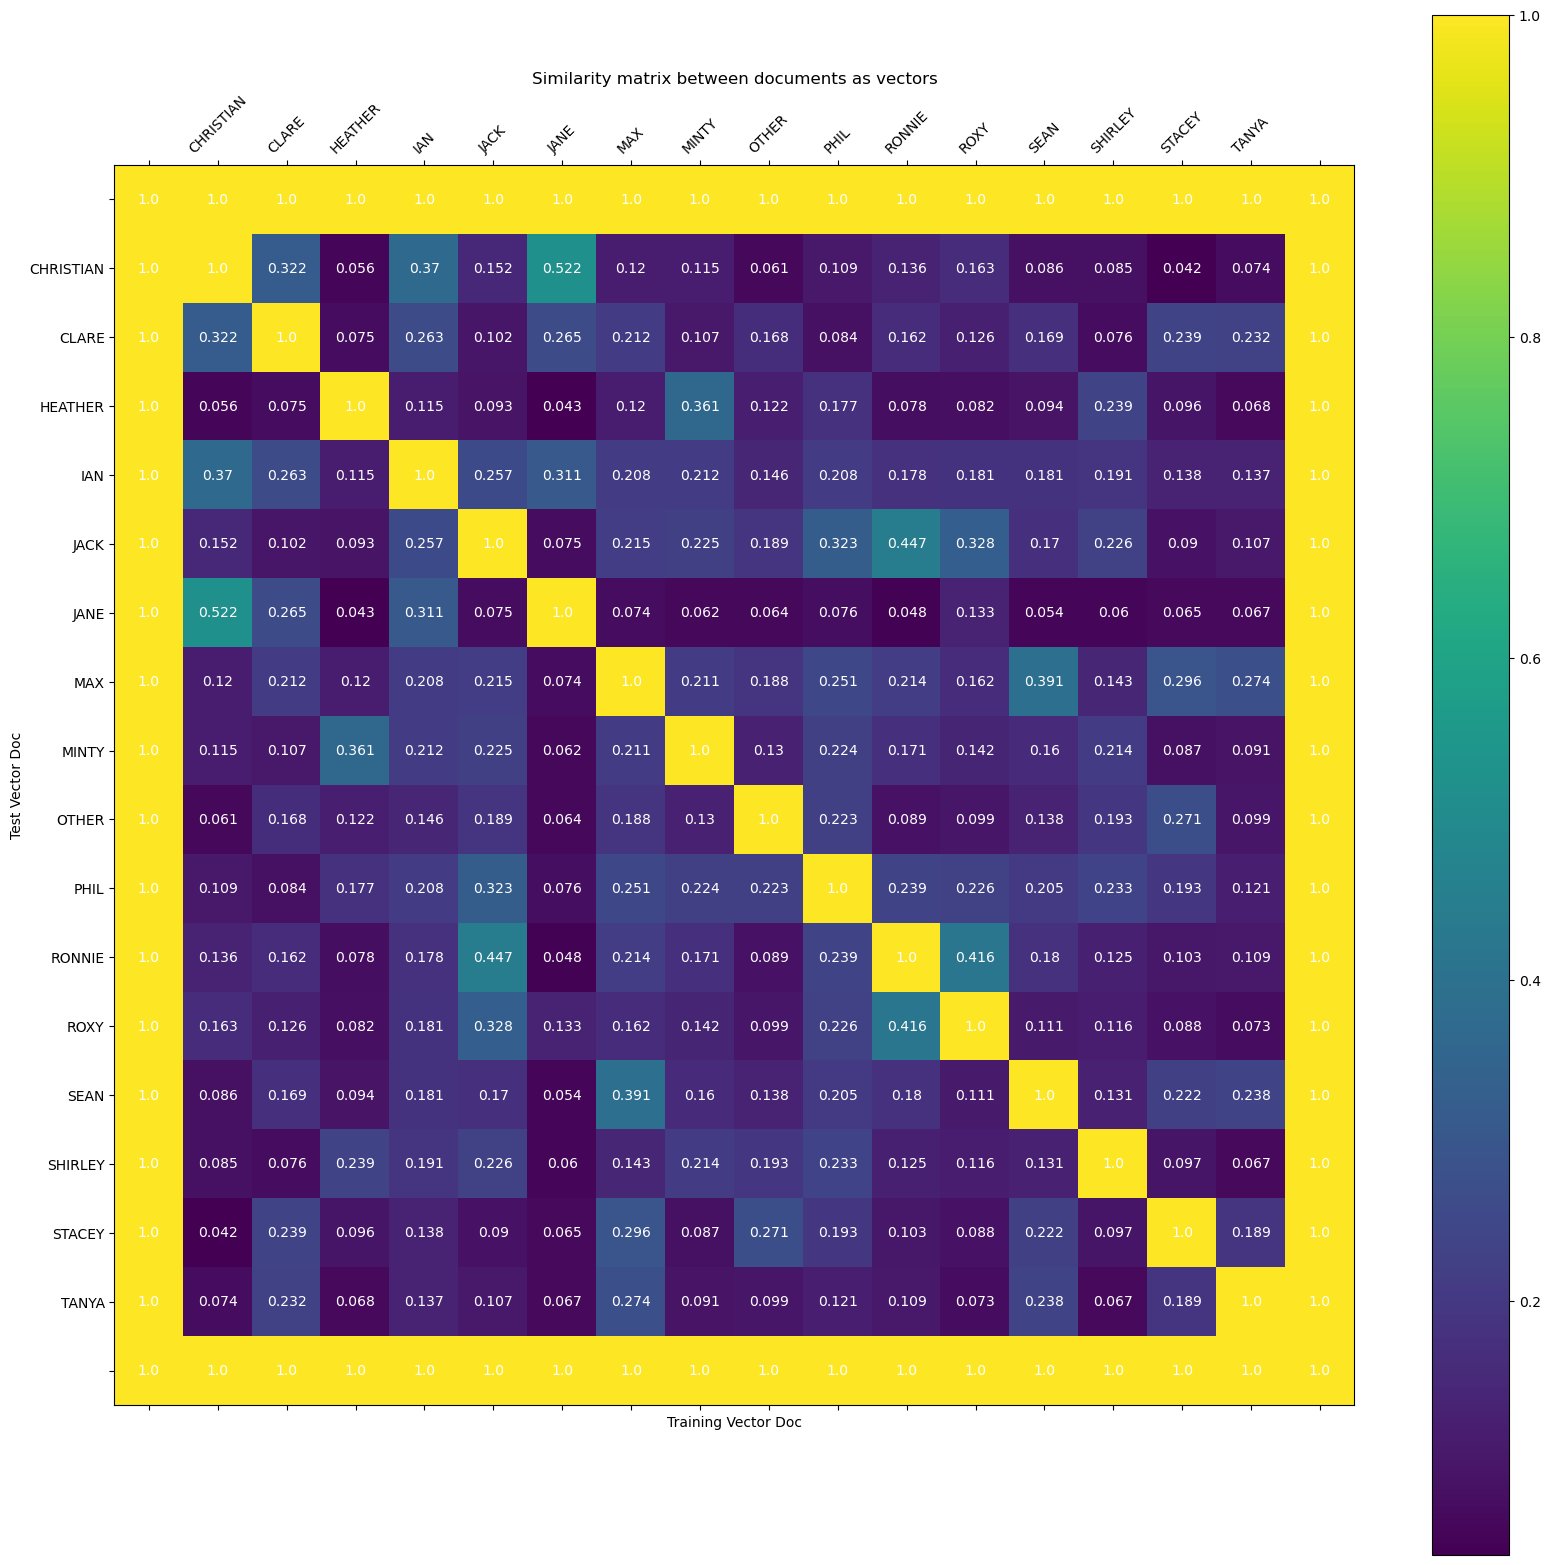

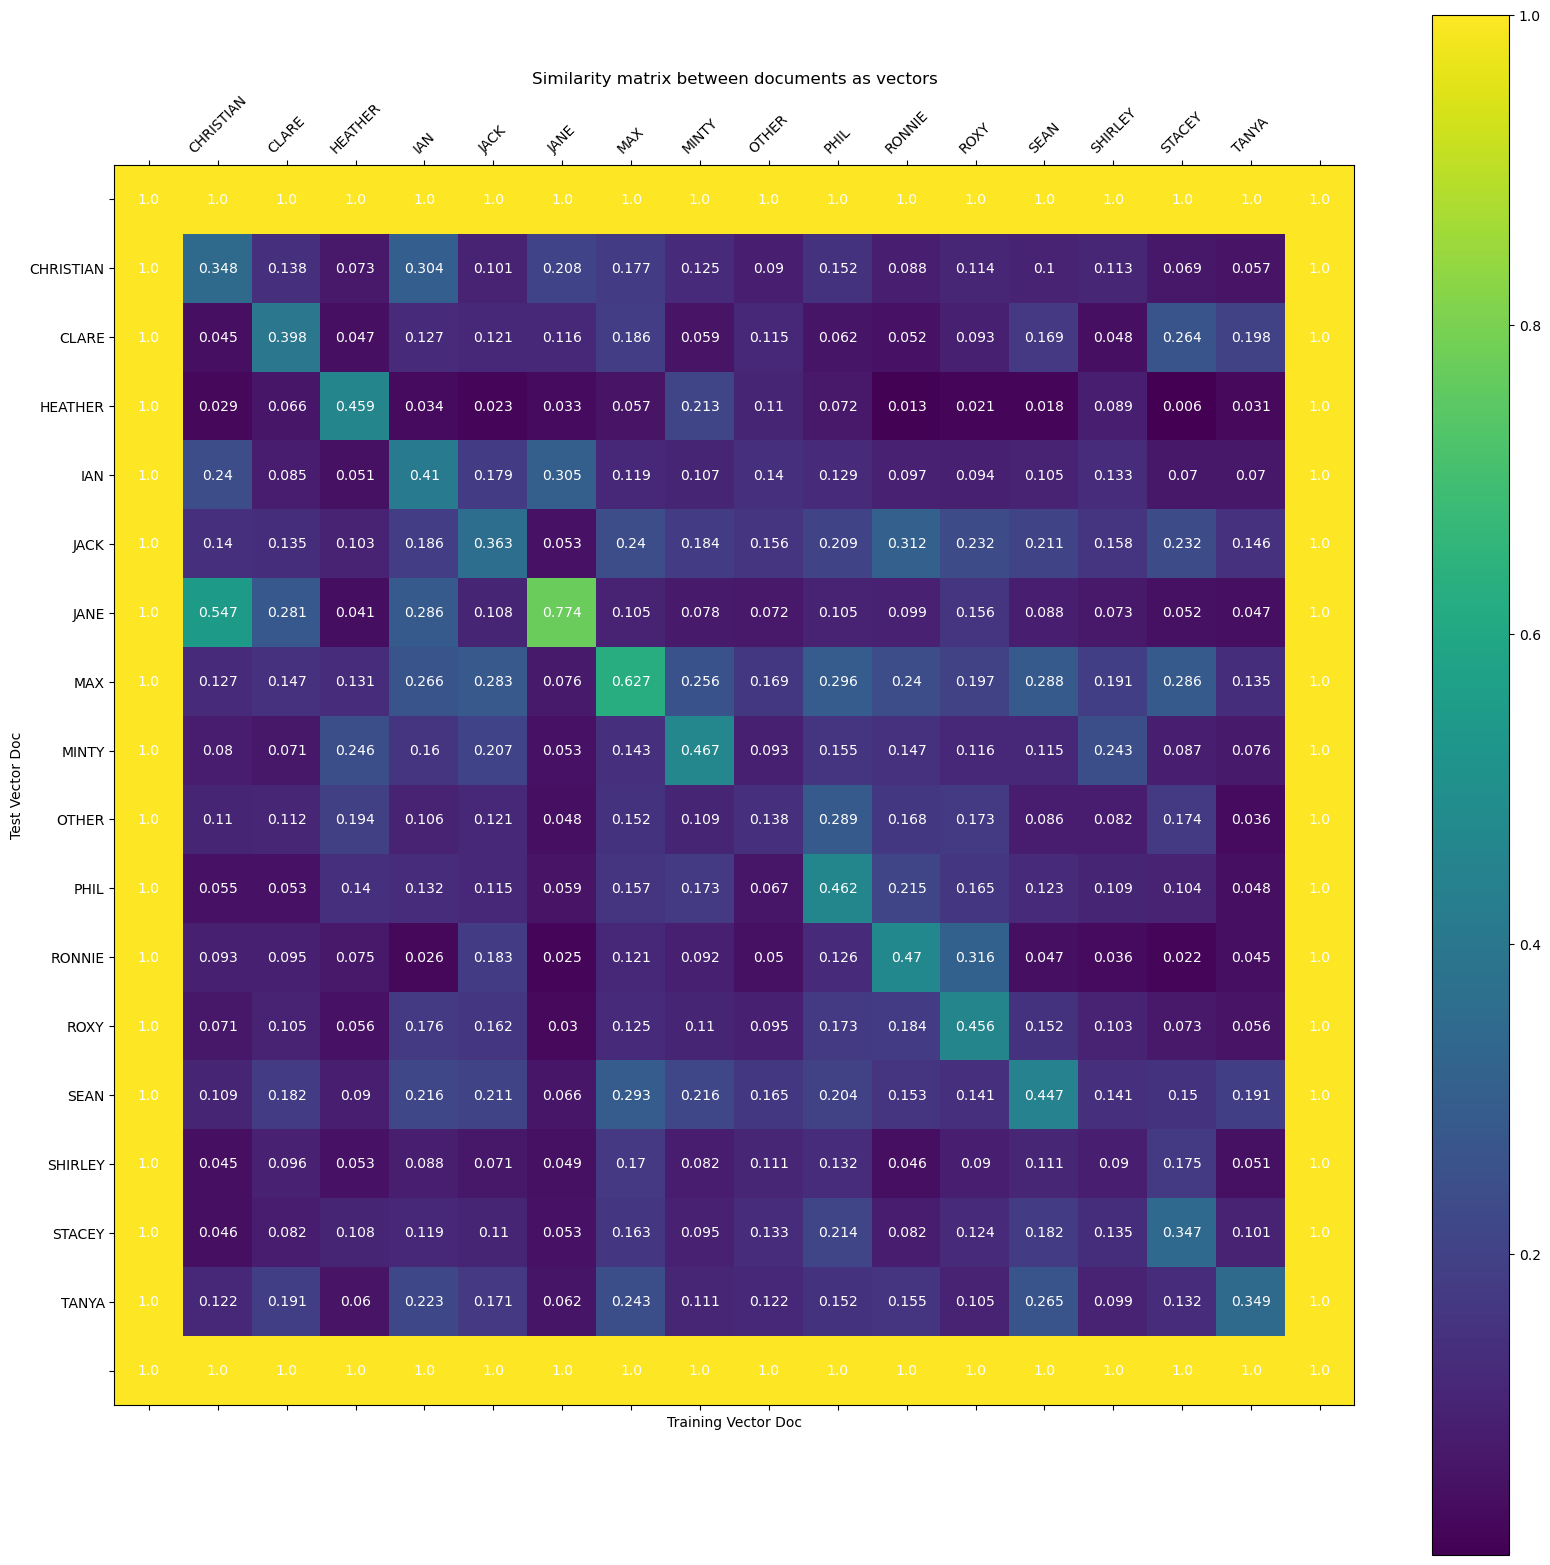

In [29]:
# plot similarity matrix train vs train
plot_heat_map_similarity(
    pd.DataFrame({
        'doc1': [train_labels[i] for i in range(len(train_labels)) for j in range(len(train_labels))],
        'doc2': [train_labels[j] for i in range(len(train_labels)) for j in range(len(train_labels))],
        'similarity': [
            compute_cosine_similarity(
                training_feature_matrix[i].toarray().flatten(),
                training_feature_matrix[j].toarray().flatten()
            )
            for i in range(len(train_labels)) for j in range(len(train_labels))
        ]
    })
)
# plot similarity matrix val vs train
plot_heat_map_similarity(
    pd.DataFrame({
        'doc1': [val_labels[i] for i in range(len(val_labels)) for j in range(len(train_labels))],
        'doc2': [train_labels[j] for i in range(len(val_labels)) for j in range(len(train_labels))],
        'similarity': [
            compute_cosine_similarity(
                val_feature_matrix[i].toarray().flatten(),
                training_feature_matrix[j].toarray().flatten()
            )
            for i in range(len(val_labels)) for j in range(len(train_labels))
        ]
    })
)


## Part 6: Run on final test data
Test your best system using the code below to train on the training data (using the first 300 lines per character maximum) and do the final testing on the test file (using the first 50 lines per character maximum).

Make any necessary adjustments such that it runs in the same way as the training/testing regime you developed above- e.g. making sure any transformer objects are initialized before `create_document_matrix_from_corpus` is called. Make sure your best system is left in the notebook and it is clear what the mean rank and accuracy of document selection are on the test data.

In [30]:
# training data with the best parameters
train_character_docs = create_character_document_from_dataframe(
    train_data, 
    max_line_count=q3_best_params['max_line_count'], 
    include_context=q3_best_params['include_context']
)
print('Num. Characters in Training Set:', len(train_character_docs.keys()), "\n")
total_words = 0
for name in train_character_docs.keys():
    print(f"{name} -> Number of Words: {len(train_character_docs[name].split())}")
    total_words += len(train_character_docs[name].split())
print(f"Total Words in Training Set: {total_words}")

# training data
training_corpus = [(name, pre_process(doc, **q1_best_params)) for name, doc in sorted(train_character_docs.items())]
train_labels = [name for name, doc in training_corpus]

# training feature matrix
training_feature_matrix = create_document_matrix_from_corpus(
    training_corpus, 
    fitting=True, 
    ngram_range=q2_best_params['ngram_range'], 
    use_pos_tags=q2_best_params['use_pos_tags'], 
    use_sentiment=q2_best_params['use_sentiment'], 
    max_df=q2_best_params.get('max_df'), 
    min_df=q2_best_params.get('min_df'),
    k_best_features=q2_best_params.get('k_best_features')
)

#test data with the best parameters
test_character_docs = create_character_document_from_dataframe(
    test_data, 
    max_line_count=50,
    include_context=q3_best_params['include_context']
)
print('Num. Characters in Test Set:', len(test_character_docs.keys()), "\n")
total_words = 0
for name in test_character_docs.keys():
    print(f"{name} -> Number of Words: {len(test_character_docs[name].split())}")
    total_words += len(test_character_docs[name].split())
print(f"Total Words in Test Set: {total_words}")

# preprocess test data
test_corpus = [(name, pre_process(doc, **q1_best_params)) for name, doc in sorted(test_character_docs.items())]
test_labels = [name for name, doc in test_corpus]

# test feature matrix
test_feature_matrix = create_document_matrix_from_corpus(
    test_corpus, 
    fitting=False, 
    ngram_range=q2_best_params['ngram_range'], 
    use_pos_tags=q2_best_params['use_pos_tags'], 
    use_sentiment=q2_best_params['use_sentiment'], 
    max_df=q2_best_params.get('max_df'),
    min_df=q2_best_params.get('min_df'),
    k_best_features=q2_best_params.get('k_best_features')
)

# the best system on the test data
mean_rank, mean_cosine_similarity, acc, df = compute_IR_evaluation_scores(
    training_feature_matrix, 
    test_feature_matrix, 
    train_labels, 
    test_labels
)

# evaluation results
print(f"\nMean Rank: {mean_rank:.2f}")
print(f"Mean Cosine Similarity: {mean_cosine_similarity:.2f}")
print(f"Accuracy: {acc:.2%}")


Num. Characters in Training Set: 16 

SHIRLEY -> Number of Words: 3400
OTHER -> Number of Words: 2973
JACK -> Number of Words: 4007
RONNIE -> Number of Words: 3305
ROXY -> Number of Words: 3419
TANYA -> Number of Words: 3591
SEAN -> Number of Words: 3168
MAX -> Number of Words: 4184
IAN -> Number of Words: 3767
JANE -> Number of Words: 3428
STACEY -> Number of Words: 3535
PHIL -> Number of Words: 3429
HEATHER -> Number of Words: 3562
MINTY -> Number of Words: 3610
CHRISTIAN -> Number of Words: 3578
CLARE -> Number of Words: 3923
Total Words in Training Set: 56879
Num. Characters in Test Set: 16 

SHIRLEY -> Number of Words: 503
OTHER -> Number of Words: 584
HEATHER -> Number of Words: 679
PHIL -> Number of Words: 495
SEAN -> Number of Words: 623
TANYA -> Number of Words: 670
MAX -> Number of Words: 714
JACK -> Number of Words: 556
IAN -> Number of Words: 643
JANE -> Number of Words: 551
STACEY -> Number of Words: 824
ROXY -> Number of Words: 533
RONNIE -> Number of Words: 520
CHRISTIAN